# IRWA Final Project — Part 1: Text Processing and Exploratory Data Analysis

In [1]:
import sys
import collections
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from wordcloud import WordCloud

# project root = first parent folder containing the `myapp` package
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "myapp").is_dir())
sys.path.insert(0, str(ROOT))

from myapp.search.load_corpus import load_corpus
from myapp.search.preprocessing import (build_terms, normalize_text, tokenize, details_to_text, preprocess_corpus,
                                        STOP_WORDS, STEMMER, DETAIL_KEYS)

DATA_PATH = ROOT / "data" / "fashion_products_dataset.json"
LABELS_PATH = ROOT / "data" / "validation_labels.csv"
PROCESSED_PATH = ROOT / "data" / "processed_corpus.pkl"
FIG_DIR = ROOT / "project_progress" / "part_1" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)


def save_fig(name):
    # save the current figure for the report
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

---
# PART 1: Data preparation

## 1.1 Load the corpus

In [2]:
# raw: original JSON (strings); corpus: pid -> Document with parsed prices/discount/rating
raw = pd.read_json(DATA_PATH)
corpus = load_corpus(str(DATA_PATH))
print("documents:", len(raw), "| unique pid:", raw.pid.nunique())
raw.head(3)

documents: 28080 | unique pid: 28080


,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:51,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,69% off,[https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/z/y/n/m-10...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Poc...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itmd2c76a...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,66% off,[https://rukminim1.flixcart.com/image/128/128/kfyasnk0/track-pant/g/5/y/s-19...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Drawstring, Elastic'}, {'Pockets':...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue-track-pants/p/itmfczez7v6rzwe...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,68% off,[https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/e/c/s/xl-1...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Poc...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itm1eee3c...


## 1.2 Text pre-processing pipeline

In [3]:
# step-by-step pre-processing of one product (title + description)
example = corpus["TKPFCZ9EA7H5FYZH"]
text = example.title + " " + example.description
normalized = normalize_text(text)
tokens = tokenize(normalized)
no_stop = [t for t in tokens if t not in STOP_WORDS]
stemmed = [STEMMER.stem(t) for t in no_stop]

print("RAW:        ", text, "\n")
print("NORMALIZED: ", normalized, "\n")
print("TOKENS:     ", tokens, "\n")
print("NO STOP:    ", no_stop, "\n")
print("STEMMED:    ", stemmed)

RAW:         Solid Women Multicolor Track Pants Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India 

NORMALIZED:  solid women multicolor track pants yorker trackpants made from 100  rich combed cotton giving it a rich look designed for comfort skin friendly fabric itch free waistband   great for all year round use proudly made in india 

TOKENS:      ['solid', 'women', 'multicolor', 'track', 'pants', 'yorker', 'trackpants', 'made', 'from', 'rich', 'combed', 'cotton', 'giving', 'it', 'rich', 'look', 'designed', 'for', 'comfort', 'skin', 'friendly', 'fabric', 'itch', 'free', 'waistband', 'great', 'for', 'all', 'year', 'round', 'use', 'proudly', 'made', 'in', 'india'] 

NO STOP:     ['solid', 'women', 'multicolor', 'track', 'pants', 'yorker', 'trackpants', 'made', 'rich', 'combed', 'cotton', 'giving', 'rich', 'look', 'designed', 'comfort', 'skin', 'frie

In [4]:
# the same function is applied to queries
for q in ["women full sleeve sweatshirt cotton", "men slim jeans blue", "Men's Slim-Fit T-Shirts", "ladies polycotton tees"]:
    print(f"{q!r:40} -> {build_terms(q)}")

'women full sleeve sweatshirt cotton'    -> ['women', 'full', 'sleev', 'sweatshirt', 'cotton']
'men slim jeans blue'                    -> ['men', 'slim', 'jean', 'blue']
"Men's Slim-Fit T-Shirts"                -> ['men', 'slim', 'fit', 'tshirt']
'ladies polycotton tees'                 -> ['women', 'poli', 'cotton', 'tee']


### Effect of each step on the vocabulary

In [5]:
# vocabulary size and number of tokens after each step, over title + description
texts = (raw.title + " " + raw.description.fillna("")).tolist()

steps = {
    "raw (whitespace split)": lambda t: t.split(),
    "+ lowercase, normalization, punctuation, tokenization": lambda t: tokenize(normalize_text(t)),
    "+ stop-word removal": lambda t: build_terms(t, stemming=False),
    "+ stemming": lambda t: build_terms(t),
}
rows = []
for name, fn in steps.items():
    toks = [tok for t in texts for tok in fn(t)]
    rows.append({"step": name, "tokens": len(toks), "vocabulary": len(set(toks))})
vocab_steps = pd.DataFrame(rows)
vocab_steps

,step,tokens,vocabulary
0,raw (whitespace split),1017425,13521
1,"+ lowercase, normalization, punctuation, tokenization",986146,6325
2,+ stop-word removal,687984,6205
3,+ stemming,687984,4741


## 1.3 Pre-process the whole corpus

In [6]:
# one row per document, saved to be loaded by the indexing in Part 2
processed = preprocess_corpus(corpus)
processed.to_pickle(PROCESSED_PATH)
print(processed.shape, "->", PROCESSED_PATH)
processed[["pid", "title", "title_terms", "details_terms", "brand_terms", "sub_category_terms"]].head()

(28080, 21) -> C:\Users\guill\OneDrive\Escritorio\Recuperació de la Informació i Anàlisi de la Web\irwa-final-project\irwa-final-project\data\processed_corpus.pkl


,pid,title,title_terms,details_terms,brand_terms,sub_category_terms
TKPFCZ9EA7H5FYZH,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]","[cotton, blend, solid, multicolor, elast]",[york],[bottomwear]
TKPFCZ9EJZV2UVRZ,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,"[solid, men, blue, track, pant]","[cotton, blend, solid, blue, drawstr, elast]",[york],[bottomwear]
TKPFCZ9EHFCY5Z4Y,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant]","[cotton, blend, solid, multicolor, elast]",[york],[bottomwear]
TKPFCZ9ESZZ7YWEF,TKPFCZ9ESZZ7YWEF,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]","[cotton, blend, solid, multicolor, elast]",[york],[bottomwear]
TKPFCZ9EVXKBSUD7,TKPFCZ9EVXKBSUD7,"Solid Women Brown, Grey Track Pants","[solid, women, brown, grey, track, pant]","[cotton, blend, solid, brown, grey, drawstr, elast]",[york],[bottomwear]


## 1.4 Handling `category`, `sub_category`, `brand`, `product_details` and `seller`

In [7]:
# how distinctive is each field, if the most frequent value covers most documents, its IDF is ~0
def field_profile(series):
    s = series.dropna().astype(str)
    s = s[s.str.strip() != ""]
    return {"non-empty %": round(100 * len(s) / len(series), 1), "distinct values": s.nunique(),
            "most frequent": s.value_counts().index[0], "most frequent %": round(100 * s.value_counts().iloc[0] / len(s), 1)}

details_text = processed.product_details.apply(details_to_text)
profile = pd.DataFrame({
    "category": field_profile(raw.category),
    "sub_category": field_profile(raw.sub_category),
    "brand": field_profile(raw.brand),
    "seller": field_profile(processed.seller),
    "product_details (selected values)": field_profile(details_text),
}).T
profile

,non-empty %,distinct values,most frequent,most frequent %
category,100.0,4,Clothing and Accessories,96.6
sub_category,100.0,24,Topwear,54.5
brand,92.8,324,ECKO Unl,3.6
seller,94.1,498,RetailNet,5.4
product_details (selected values),98.1,10359,Cotton Blend Solid Half Sleeve Polo Neck Men Regular T Shirts Polo Neck,0.9


In [8]:
# % of labelled documents (validation_labels.csv) with each query term in each field
labels = pd.read_csv(LABELS_PATH)
QUERIES = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
FIELDS = ["title_terms", "description_terms", "details_terms", "sub_category_terms", "brand_terms"]
lab = labels.merge(processed.drop(columns="title"), on="pid")

rows = []
for qid, query in QUERIES.items():
    sub = lab[lab.query_id == qid]
    for term in build_terms(query):
        row = {"query": qid, "term": term}
        for f in FIELDS:
            row[f.replace("_terms", "")] = f"{100 * sub[f].apply(lambda ts: term in ts).mean():.0f}%"
        rows.append(row)
print("% of labelled documents containing the query term in each field")
pd.DataFrame(rows)

% of labelled documents containing the query term in each field


,query,term,title,description,details,sub_category,brand
0,1,women,100%,40%,20%,0%,0%
1,1,full,80%,50%,80%,0%,0%
2,1,sleev,80%,50%,100%,0%,0%
3,1,sweatshirt,80%,65%,20%,0%,0%
4,1,cotton,0%,100%,90%,0%,0%
5,2,men,45%,0%,45%,0%,0%
6,2,slim,60%,45%,10%,0%,0%
7,2,jean,100%,65%,70%,0%,0%
8,2,blue,100%,40%,100%,0%,0%


In [9]:
# AND relevant / non-relevant labelled documents retrieved per set of indexed fields
def and_match(doc_terms, query_terms):
    return set(query_terms) <= set(doc_terms)

field_sets = {
    "title only": ["title_terms"],
    "title + description": ["title_terms", "description_terms"],
    "title + description + details": ["title_terms", "description_terms", "details_terms"],
    "all fields (terms)": ["terms"],
}
rows = []
for qid, query in QUERIES.items():
    q = build_terms(query)
    sub = lab[lab.query_id == qid]
    for name, fields in field_sets.items():
        matched = sub.apply(lambda r: and_match(sum((r[f] for f in fields), []), q), axis=1)
        rows.append({"query": qid, "indexed fields": name,
                     "relevant docs matched": f"{(matched & (sub.labels == 1)).sum()}/{(sub.labels == 1).sum()}",
                     "non-relevant docs matched": f"{(matched & (sub.labels == 0)).sum()}/{(sub.labels == 0).sum()}"})
pd.DataFrame(rows)

,query,indexed fields,relevant docs matched,non-relevant docs matched
0,1,title only,0/13,0/7
1,1,title + description,13/13,7/7
2,1,title + description + details,13/13,7/7
3,1,all fields (terms),13/13,7/7
4,2,title only,4/10,1/10
5,2,title + description,6/10,2/10
6,2,title + description + details,6/10,2/10
7,2,all fields (terms),6/10,2/10


In [10]:
# documents returned by each AND query over the whole corpus, per set of indexed fields
rows = []
for qid, query in QUERIES.items():
    q = build_terms(query)
    row = {"query": query}
    for name, fields in field_sets.items():
        row[name] = processed.apply(lambda r: and_match(sum((r[f] for f in fields), []), q), axis=1).sum()
    rows.append(row)
pd.DataFrame(rows).set_index("query")

,title only,title + description,title + description + details,all fields (terms)
query,,,,
women full sleeve sweatshirt cotton,0,241,549,549
men slim jeans blue,116,176,217,217


## 1.5 Handling `out_of_stock`, `selling_price`, `discount`, `actual_price`, `average_rating`

In [11]:
# missing values after parsing, and reported discount vs discount derived from the prices
NUM = ["selling_price", "actual_price", "discount", "average_rating"]
print("missing values after parsing:")
print(processed[NUM].isna().sum().to_string(), "\n")

# consistency check: reported discount vs discount derived from prices
derived = 100 * (1 - processed.selling_price / processed.actual_price)
reported = pd.to_numeric(raw.set_index("pid").discount.str.extract(r"(\d+)")[0], errors="coerce").reindex(processed.index)
diff = (derived - reported).abs()
print(f"reported vs derived discount, |diff| <= 1 point: {(diff <= 1).mean():.1%} of documents with both values")
print(f"discounts filled from prices: {(reported.isna() & processed.discount.notna()).sum()}")
processed[NUM].describe().round(2)

missing values after parsing:
selling_price        2
actual_price       777
discount           777
average_rating    2261 

reported vs derived discount, |diff| <= 1 point: 96.9% of documents with both values
discounts filled from prices: 78


,selling_price,actual_price,discount,average_rating
count,28078.00,27303.00,27303.00,25819.00
mean,705.64,1455.53,50.11,3.63
std,549.68,939.98,17.07,0.66
min,99.00,150.00,0.00,1.00
25%,390.00,849.00,40.00,3.20
50%,545.00,1199.00,52.00,3.80
75%,820.00,1799.00,63.00,4.10
max,7999.00,12999.00,87.00,5.00


---
# PART 2: Exploratory Data Analysis

## 2.1 Overview and missing values

In [12]:
# a value is missing if it is None/NaN or an empty string/list
def is_missing(value):
    if value is None:
        return True
    if isinstance(value, float) and np.isnan(value):
        return True
    if isinstance(value, str) and len(value) == 0:
        return True
    if isinstance(value, list) and len(value) == 0:
        return True
    return False

print("documents:", len(raw))

# number of products per category
category_counts = raw["category"].value_counts()
print("categories:", category_counts.to_dict())

# 5 most frequent sub-categories
sub_category_counts = raw["sub_category"].value_counts()
print("top sub-categories:", sub_category_counts.head(5).to_dict())

# % of missing values in each column (only the columns with some missing value)
missing = {}
for column in raw.columns:
    n_missing = 0
    for value in raw[column]:
        if is_missing(value):
            n_missing += 1
    percentage = round(100 * n_missing / len(raw), 1)
    if percentage > 0:
        missing[column] = percentage

missing = pd.DataFrame.from_dict(missing, orient="index", columns=["% missing"])
missing.sort_values("% missing", ascending=False)

documents: 28080
categories: {'Clothing and Accessories': 27118, 'Footwear': 920, 'Bags, Wallets & Belts': 41, 'Toys': 1}
top sub-categories: {'Topwear': 15310, 'Bottomwear': 3666, 'Winter Wear': 2493, 'Innerwear and Swimwear': 1762, 'Clothing Accessories': 1742}


,% missing
description,39.7
average_rating,8.1
brand,7.2
seller,5.9
discount,3.0
actual_price,2.8
images,2.7


## 2.2 Word counts, sentence length and vocabulary

avg words per title: 6.5
avg words per non-empty description: 49.4 (empty descriptions: 39.7%)
avg sentence length (descriptions): 15.7 words
vocabulary size (raw title + description): 13521
vocabulary size (processed terms, all fields): 5053


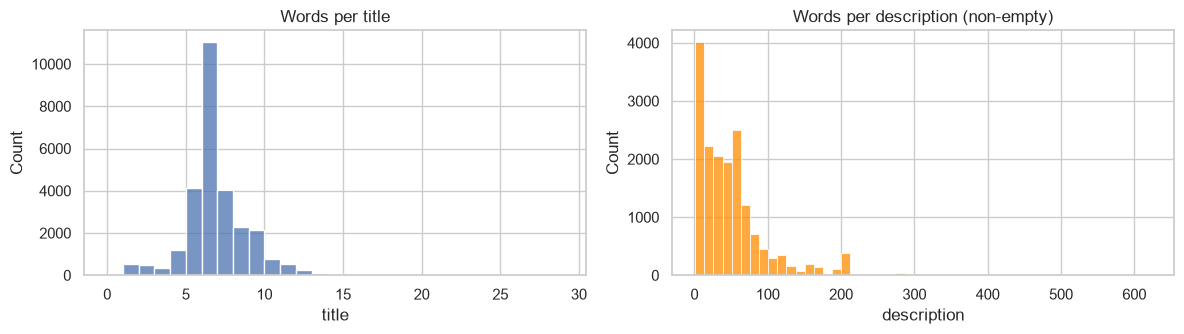

In [13]:
# number of words of each title
title_words = []
for title in raw["title"]:
    title_words.append(len(title.split()))

# non-empty descriptions and their number of words
descriptions = []
desc_words = []
for description in raw["description"]:
    if description.strip() != "":
        descriptions.append(description)
        desc_words.append(len(description.split()))

# number of words of each sentence of the descriptions
sentence_lengths = []
for description in descriptions:
    for sentence in nltk.sent_tokenize(description):
        sentence_lengths.append(len(sentence.split()))

# vocabulary = set of distinct terms after pre-processing (all fields)
vocabulary = set()
for terms in processed["terms"]:
    for term in terms:
        vocabulary.add(term)

empty_descriptions = 1 - len(descriptions) / len(raw)
print(f"avg words per title: {np.mean(title_words):.1f}")
print(f"avg words per non-empty description: {np.mean(desc_words):.1f} (empty descriptions: {empty_descriptions:.1%})")
print(f"avg sentence length (descriptions): {np.mean(sentence_lengths):.1f} words")
print("vocabulary size (raw title + description):", vocab_steps["vocabulary"][0])
print("vocabulary size (processed terms, all fields):", len(vocabulary))

# histograms of the number of words per title and per description
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(title_words, bins=range(0, 30), ax=axes[0])
axes[0].set_title("Words per title")
axes[0].set_xlabel("title")
sns.histplot(desc_words, bins=50, ax=axes[1], color="darkorange")
axes[1].set_title("Words per description (non-empty)")
axes[1].set_xlabel("description")
save_fig("word_counts")

## 2.3 Most frequent words
Top terms after pre-processing and a word cloud of titles + descriptions (unstemmed tokens for readability).

top 15 terms: [('neck', 41145), ('cotton', 33252), ('tshirt', 32008), ('round', 27604), ('women', 26572), ('men', 26213), ('sleev', 24134), ('solid', 22129), ('print', 21435), ('regular', 15709), ('topwear', 15310), ('blend', 15179), ('casual', 12277), ('wear', 11926), ('shirt', 11457)]


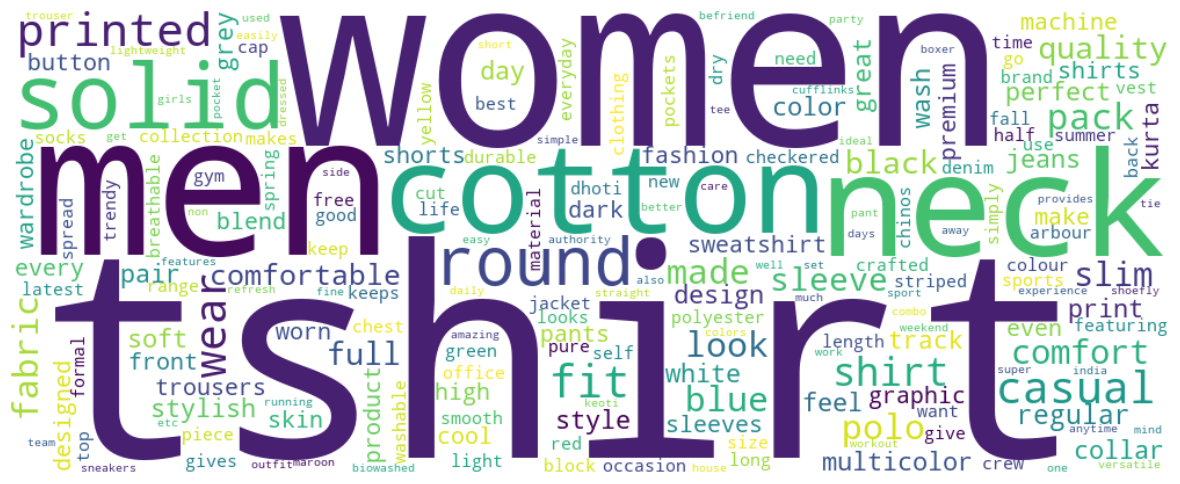

In [ ]:
# frequency of each term after pre-processing (all fields)
term_freq = {}
for terms in processed["terms"]:
    for term in terms:
        if term in term_freq:
            term_freq[term] += 1
        else:
            term_freq[term] = 1


def get_count(item):
    # item is a (term, count) pair
    return item[1]


# sort the terms from most to least frequent and keep the first 15
sorted_terms = sorted(term_freq.items(), key=get_count, reverse=True)
print("top 15 terms:", sorted_terms[:15])

# word cloud: frequency of each word of title + description
words = {}
for text in texts:
    for word in build_terms(text, stemming=False):
        if word in words:
            words[word] += 1
        else:
            words[word] = 1

wc = WordCloud(width=1000, height=400, background_color="white", random_state=42)
wc.generate_from_frequencies(words)
plt.figure(figsize=(12, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
save_fig("word_cloud")

## 2.4 Price, discount and rating

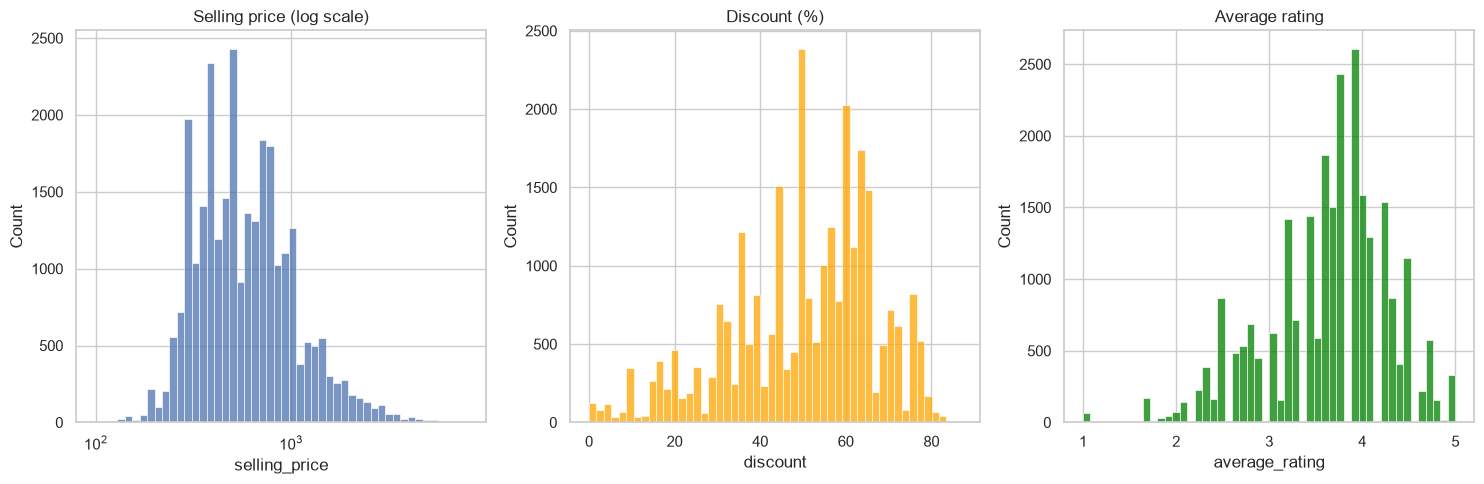

Top 5 by rating


,title,brand,selling_price,discount,average_rating
KTAFAKGUKA2SXSEQ,Men Solid Cotton Blend Pathani Kurta (Blue),Purple Sta,449.0,82.0,5.0
BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),SayItLo,249.0,78.0,5.0
TSHFNJ9ZEUZG3CPU,Printed Women Round Neck Multicolor T-Shirt,yellowvib,275.0,77.0,5.0
TSHFU5AF8KZC5FYH,Printed Women Round Neck Black T-Shirt,PixF,289.0,77.0,5.0
TSHFTT2JATXKUHEV,Solid Women Round Neck Black T-Shirt,PixF,288.0,77.0,5.0


Top 5 by price


,title,brand,selling_price,discount,average_rating
TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,REEB,7999.0,20.0,2.7
BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sleeve Blazer (Grey),True Bl,7998.0,0.0,2.6
JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,Pu,7799.0,40.0,3.7
SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,Pu,7799.0,40.0,4.5
JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,G,7794.0,40.0,4.2


Top 5 by discount


,title,brand,selling_price,discount,average_rating
TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,128.0,87.0,3.0
TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,Jack Roy,136.0,86.0,4.1
TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,Jack Roy,136.0,86.0,4.7
TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pack of 2),yellowvib,449.0,85.0,3.2
CAPE9YWMURE4FKAJ,Solid Balclava Cap,Gracew,228.0,84.0,4.3


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sns.histplot(processed.selling_price.dropna(), bins=50, log_scale=True, ax=axes[0])
axes[0].set_title("Selling price (log scale)")
sns.histplot(processed.discount.dropna(), bins=50, ax=axes[1], color="orange")
axes[1].set_title("Discount (%)")
sns.histplot(processed.average_rating.dropna(), bins=50, ax=axes[2], color="green")
axes[2].set_title("Average rating")
save_fig("numerical_distributions")

cols = ["title", "brand", "selling_price", "discount", "average_rating"]
print("Top 5 by rating") #secondly by discount
display(processed.sort_values(["average_rating", "discount"], ascending=False)[cols].head(5))
print("Top 5 by price")
display(processed.sort_values("selling_price", ascending=False)[cols].head(5))
print("Top 5 by discount")
display(processed.sort_values("discount", ascending=False)[cols].head(5))

## 2.5 Top brands and sellers, out-of-stock distribution

In [16]:
print("top brands:", raw.brand[raw.brand != ""].value_counts().head(10).to_dict())
print("top sellers:", processed.seller.value_counts().head(10).to_dict())
print("\nout of stock:", processed.out_of_stock.value_counts().to_dict(), f"({processed.out_of_stock.mean():.1%})")
processed.groupby("out_of_stock")[["selling_price", "discount", "average_rating"]].mean().round(2)

top brands: {'ECKO Unl': 951, 'Free Authori': 860, 'ARBO': 806, 'REEB': 802, 'Pu': 798, 'True Bl': 793, 'Keo': 660, 'Amp': 585, 'Black Beat': 548, 'vims rai': 503}
top sellers: {'RetailNet': 1416, 'SandSMarketing': 887, 'BioworldMerchandising': 842, 'ARBOR': 783, 'Keoti': 660, 'AFFGARMENTS': 587, 'Black Beatle': 548, 'AMALGUS ENTERPRISE': 477, 'Tayab Manch Fashions': 437, 'KAPSONSRETAILPVTLTD': 417}

out of stock: {False: 26436, True: 1644} (5.9%)


,selling_price,discount,average_rating
out_of_stock,,,
False,686.73,50.21,3.62
True,1009.93,48.60,3.92


## 2.6 Data quality and key findings

In [17]:
slug = raw.url.str.extract(r"flipkart\.com/([^/]+)/p/")[0]
print("duplicated titles:", raw.title.duplicated().sum())
print("titles saying 'Women' whose URL says 'men':",
      (raw.title.str.contains(r"\bWomen\b") & slug.str.contains(r"(?:^|-)men(?:-|$)")).sum())
print("out-of-stock products without seller:", (processed.out_of_stock & processed.seller.isna()).sum(),
      "of", processed.out_of_stock.sum())

duplicated titles: 22127


titles saying 'Women' whose URL says 'men': 13039


out-of-stock products without seller: 1643 of 1644
